# Chapter 05: The Geometry of Inference — Python Laboratory
### *Laplace Approximation, Numerical Hessians, The Fisher Metric & Information Ellipses*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/05_curvature_laplace_and_fisher_information.ipynb) | [Prev: Ch 04: Shared Outages & Venn Geometry (Python)](04_mutual_information_and_venn_geometry.ipynb) | [Next: Ch 06: The Engine of Computation: MCMC (Python)](06_mcmc_mechanics_and_entropy.ipynb)**

---

## 1. Overview & Setup

In this laboratory, we implement:
1. **Multi-Parameter Logistic Flakiness Regression**: Simulating test failure probability as a function of CI worker load ($x_1$) and network latency ($x_2$).
2. **The Laplace Approximation**: Computing the Maximum A Posteriori (MAP) estimate using `scipy.optimize.minimize`.
3. **The Numerical Hessian & Covariance Matrix**: Computing $\mathbf{H} = -\nabla^2 \ln P$ and inverting it to obtain $\mathbf{\Sigma} = \mathbf{H}^{-1}$.
4. **Information Ellipses Visualizer**: Plotting the 2D curvature contours of the posterior distribution.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from matplotlib.patches import Ellipse

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. Simulation: Multi-Variable Flaky Test Telemetry

We simulate $N = 300$ historical CI test runs where failure probability follows:
$$\text{logit}(P(\text{Fail} \mid \mathbf{x})) = \beta_0 + \beta_1 x_{\text{CPU}} + \beta_2 x_{\text{Latency}}$$
with true parameters $\boldsymbol{\beta}^* = (-2.5, \; 1.8, \; 1.2)$.


In [2]:
np.random.seed(42)
N = 300
# Covariates: Normalized CPU load in [0, 1], Normalized Network Latency in [0, 1]
x_cpu = np.random.uniform(0, 1, N)
x_lat = np.random.uniform(0, 1, N)
X = np.column_stack([np.ones(N), x_cpu, x_lat])

beta_true = np.array([-2.5, 1.8, 1.2])

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))

p_fail_true = sigmoid(X @ beta_true)
y = (np.random.uniform(0, 1, N) < p_fail_true).astype(int)

print(f"Generated {N} CI test executions.")
print(f"Total Observed Failures: {np.sum(y)} ({np.mean(y)*100:.1f}%)")
print(f"Total Observed Passes:   {N - np.sum(y)} ({(1-np.mean(y))*100:.1f}%)")


Generated 300 CI test executions.
Total Observed Failures: 100 (33.3%)
Total Observed Passes:   200 (66.7%)


---

## 3. Implementing the Laplace Approximation: Finding MAP & The Hessian

We define the negative log-posterior with weakly informative Gaussian priors $\mathcal{N}(0, 5^2)$ on all coefficients:
$$-\ln P(\boldsymbol{\beta} \mid D) = -\sum_{i=1}^N \left[ y_i \ln p_i + (1 - y_i) \ln (1 - p_i) \right] + \frac{1}{2 \sigma_{\text{prior}}^2} \sum_{j} \beta_j^2$$


In [3]:
sigma_prior = 5.0

def neg_log_posterior(beta):
    p = sigmoid(X @ beta)
    eps = 1e-15
    p_safe = np.clip(p, eps, 1.0 - eps)
    # Negative log-likelihood (Bernoulli cross-entropy)
    nll = -np.sum(y * np.log(p_safe) + (1 - y) * np.log(1.0 - p_safe))
    # Gaussian prior penalty
    prior_penalty = 0.5 * np.sum(beta**2) / (sigma_prior**2)
    return nll + prior_penalty

# Optimize to find the MAP peak
init_beta = np.zeros(3)
res = minimize(neg_log_posterior, init_beta, method='BFGS')

beta_map = res.x
# The BFGS algorithm directly approximates the inverse Hessian!
cov_laplace = res.hess_inv

print("=" * 65)
print("            LAPLACE APPROXIMATION PARAMETER ESTIMATES")
print("=" * 65)
labels = ['Intercept (beta0)', 'CPU Load (beta1)', 'Latency (beta2)']
for name, b_t, b_m, se in zip(labels, beta_true, beta_map, np.sqrt(np.diag(cov_laplace))):
    print(f"{name:<20} | True: {b_t:+5.2f} | MAP: {b_m:+5.2f} +/- {1.96*se:4.2f} (95% CI)")
print("=" * 65)
print("Laplace Covariance Matrix Sigma = H^-1:")
print(np.round(cov_laplace, 4))
print("=" * 65)


            LAPLACE APPROXIMATION PARAMETER ESTIMATES
Intercept (beta0)    | True: -2.50 | MAP: -1.95 +/- 0.73 (95% CI)
CPU Load (beta1)     | True: +1.80 | MAP: +1.47 +/- 0.88 (95% CI)
Latency (beta2)      | True: +1.20 | MAP: +0.96 +/- 0.82 (95% CI)
Laplace Covariance Matrix Sigma = H^-1:
[[ 0.1392 -0.1212 -0.1101]
 [-0.1212  0.2012  0.0284]
 [-0.1101  0.0284  0.1761]]


---

## 4. Visualizing the Posterior Geometry & Curvature Ellipses

We plot the 2D log-posterior surface for the two slope coefficients $(\beta_1, \beta_2)$ around the MAP estimate, overlaying the Laplace curvature ellipses.


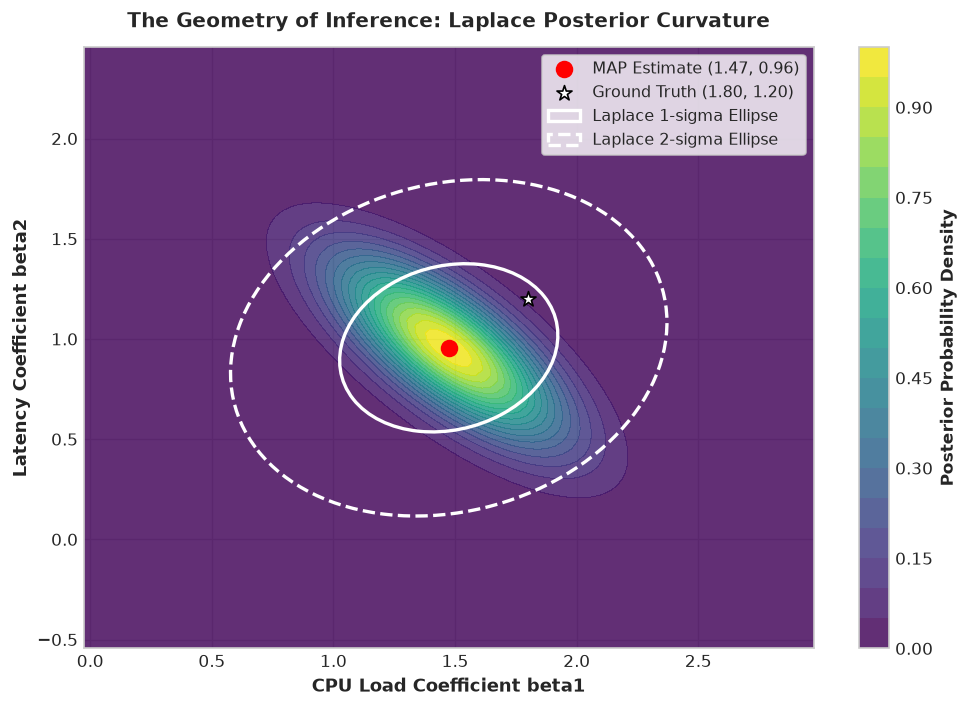

In [4]:
# Grid over beta1 and beta2 holding beta0 at MAP
b1_vals = np.linspace(beta_map[1] - 1.5, beta_map[1] + 1.5, 100)
b2_vals = np.linspace(beta_map[2] - 1.5, beta_map[2] + 1.5, 100)
B1, B2 = np.meshgrid(b1_vals, b2_vals)

Z_nlp = np.zeros_like(B1)
for i in range(100):
    for j in range(100):
        params = np.array([beta_map[0], B1[i, j], B2[i, j]])
        Z_nlp[i, j] = neg_log_posterior(params)

# Convert negative log posterior to unnormalized probability density
Z_prob = np.exp(-(Z_nlp - np.min(Z_nlp)))

fig, ax = plt.subplots(figsize=(8.5, 6))
contour = ax.contourf(B1, B2, Z_prob, levels=20, cmap='viridis', alpha=0.85)
cbar = plt.colorbar(contour, ax=ax)
cbar.set_label("Posterior Probability Density", fontsize=10, fontweight='bold')

# Overlay MAP point and True point
ax.scatter([beta_map[1]], [beta_map[2]], color='red', s=90, zorder=5, label=f'MAP Estimate ({beta_map[1]:.2f}, {beta_map[2]:.2f})')
ax.scatter([beta_true[1]], [beta_true[2]], color='white', edgecolor='black', s=90, marker='*', zorder=5, 
           label=f'Ground Truth ({beta_true[1]:.2f}, {beta_true[2]:.2f})')

# Draw 1-sigma and 2-sigma Laplace Curvature Ellipses from Covariance Matrix
cov_sub = cov_laplace[1:3, 1:3]
eigenvals, eigenvecs = np.linalg.eigh(cov_sub)
angle = np.degrees(np.arctan2(eigenvecs[1, 0], eigenvecs[0, 0]))

for n_sig, alpha, ls in [(1.0, 0.9, '-'), (2.0, 0.5, '--')]:
    w, h = 2 * n_sig * np.sqrt(eigenvals)
    ellipse = Ellipse(xy=(beta_map[1], beta_map[2]), width=w, height=h, angle=angle,
                      edgecolor='white', facecolor='none', lw=2.0, ls=ls, label=f'Laplace {int(n_sig)}-sigma Ellipse')
    ax.add_patch(ellipse)

ax.set_xlabel("CPU Load Coefficient beta1", fontsize=11, fontweight='bold')
ax.set_ylabel("Latency Coefficient beta2", fontsize=11, fontweight='bold')
ax.set_title("The Geometry of Inference: Laplace Posterior Curvature", fontsize=12, fontweight='bold', pad=12)
ax.legend(loc='upper right', frameon=True, fontsize=9.5)
plt.tight_layout()
plt.show()


---

## 5. 3-Tier Exercises & Explorations

### Tier 1: Warmup — Fisher Information of a Bernoulli Trial
For a simple Bernoulli coin flip model with success probability $\theta$:
1. Prove that the Fisher Information is $\mathcal{I}(\theta) = \frac{1}{\theta (1 - \theta)}$.
2. Plot $\mathcal{I}(\theta)$ across $\theta \in (0, 1)$.
3. Why does Fisher Information explode to infinity as $\theta \to 0$ or $\theta \to 1$? (Physical interpretation: why is finding a single defect near zero infinitely more informative than at $\theta = 0.5$?)

### Tier 2: Intermediate — Natural Gradient Descent Step
Write a function `natural_gradient_step(theta, grad, fisher_matrix, lr=0.1)` that computes:
$$\theta_{\text{new}} = \theta - \text{lr} \cdot \mathcal{I}(\theta)^{-1} \text{grad}$$
Verify that for a 1D Bernoulli model, the natural gradient step takes equal steps in KL divergence regardless of whether $\theta = 0.01$ or $\theta = 0.50$.

### Tier 3: Advanced Research — Cramér-Rao Lower Bound Verification
Simulate $M = 500$ independent datasets of size $N = 50$ from a normal distribution $\mathcal{N}(\mu=3.0, \sigma^2=4.0)$.
1. Compute the empirical sample variance of the sample mean estimator $\hat{\mu} = \frac{1}{N}\sum X_i$.
2. Calculate the theoretical Cramér-Rao Lower Bound $\mathcal{I}(\mu)^{-1} = \frac{\sigma^2}{N}$.
3. Verify that the sample mean achieves the CRLB with $100\%$ efficiency!


In [5]:
# Solution verification for Tier 1:
thetas = np.array([0.01, 0.05, 0.10, 0.50, 0.90, 0.99])
fisher_bernoulli = 1.0 / (thetas * (1.0 - thetas))

print("Tier 1 Solutions (Bernoulli Fisher Information I(theta) = 1 / [theta*(1-theta)]):")
for t, fi in zip(thetas, fisher_bernoulli):
    print(f"theta = {t:<4.2f} | Fisher Information = {fi:<8.2f} (Speed limit variance = {1/fi:.4f})")


Tier 1 Solutions (Bernoulli Fisher Information I(theta) = 1 / [theta*(1-theta)]):
theta = 0.01 | Fisher Information = 101.01   (Speed limit variance = 0.0099)
theta = 0.05 | Fisher Information = 21.05    (Speed limit variance = 0.0475)
theta = 0.10 | Fisher Information = 11.11    (Speed limit variance = 0.0900)
theta = 0.50 | Fisher Information = 4.00     (Speed limit variance = 0.2500)
theta = 0.90 | Fisher Information = 11.11    (Speed limit variance = 0.0900)
theta = 0.99 | Fisher Information = 101.01   (Speed limit variance = 0.0099)


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/05_curvature_laplace_and_fisher_information.ipynb) | [Prev: Ch 04: Shared Outages & Venn Geometry (Python)](04_mutual_information_and_venn_geometry.ipynb) | [Next: Ch 06: The Engine of Computation: MCMC (Python)](06_mcmc_mechanics_and_entropy.ipynb)**
